# Permit category and issuance time: EDA and hypothesis testing

This notebook investigates whether filing-to-issuance times differ across San Francisco construction permit categories. The integrated file has one row per permit, not one row per construction site. Read `README.txt` and `metadata/data_dictionary.csv` for source details and limits.

**Interpretation:** filing-to-issuance includes agency and applicant time and payment waits. The main duration analysis includes permits with valid recorded issuance dates only; it does not estimate time for permits without a recorded issuance. The result is observational and does not show that permit category causes delays.


## 1. Load the data

Start Jupyter in the project folder if possible. The path check also looks in parent folders. Keep ID-like values as text so parcel and permit codes are not altered.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from IPython.display import display
from scipy import stats

sns.set_theme(style="whitegrid", context="notebook")
DATA_FILE = Path("data/construction_permits_ssot.csv.gz")
if not DATA_FILE.exists():
    for parent in Path.cwd().parents:
        candidate = parent / "data" / "construction_permits_ssot.csv.gz"
        if candidate.exists():
            DATA_FILE = candidate
            break
if not DATA_FILE.exists():
    raise FileNotFoundError("Could not find data/construction_permits_ssot.csv.gz. Start Jupyter in the project folder.")

ID_COLUMNS = ["permit_number", "block", "lot", "parcel_block_key", "parcel_lot_key",
              "assessor_block", "assessor_lot", "assessor_parcel_number", "record_id",
              "assessor_row_id", "zipcode"]
df = pd.read_csv(DATA_FILE, keep_default_na=False, na_values=[""],
                 dtype={c: "string" for c in ID_COLUMNS}, low_memory=False)
print(f"Loaded {len(df):,} permit rows and {len(df.columns):,} columns")
display(df.head())


Loaded 154,689 permit rows and 95 columns


,permit_number,permit_type,permit_type_definition,permit_creation_date,block,lot,street_number,street_number_suffix,street_name,street_suffix,...,invalid_issuance_chronology,has_recorded_issuance,observed_at_least_365_days,issued_within_365_days,building_age_at_filing,building_age_group,estimated_cost_2024_usd_cpi,estimate_revision_usd,estimate_revision_pct,snapshot_date_utc
0,201806081423,8,otc alterations permit,2018-06-08T00:00:00.000,1139,005,167,NaN,Stanyan,Bl,...,True,True,True,NaN,82.0,60-99 years,4910.057341,0.0,0.000000,2026-10-22
1,201812067576,3,additions alterations or repairs,2018-12-06T00:00:00.000,2822A,035,85,NaN,Midcrest,Wy,...,False,True,True,True,57.0,30-59 years,186933.181573,0.0,0.000000,2026-10-22
2,201901029418,8,otc alterations permit,2019-01-02T00:00:00.000,0492,012,2036,NaN,Lombard,St,...,False,True,True,True,60.0,60-99 years,10592.880289,500.0,5.882353,2026-10-22
3,201901029420,8,otc alterations permit,2019-01-02T00:00:00.000,5656,036,69,NaN,Nebraska,St,...,False,True,True,True,49.0,30-59 years,13085.322710,0.0,0.000000,2026-10-22
4,201901029419,8,otc alterations permit,2019-01-02T00:00:00.000,3713,007,1,NaN,Market,St,...,False,True,True,True,40.0,30-59 years,790.104247,0.0,0.000000,2026-10-22


### What this shows

The file loaded with **154,689 rows and 95 columns**. The preview shows that the records include very different permit categories, from over-the-counter alterations to additions. This is an administrative permit dataset, not a count of unique building sites. The notebook keeps identifiers as text so codes such as parcel lots remain intact.


## 2. Initial data audit

Check grain, duplicates, missingness, and raw column types. The project package documents one row per unique permit number. Duplicate row checks are diagnostic; do not drop records just because a value looks unusual.


In [2]:
print("Shape:", df.shape)
print("Unique permit numbers:", df["permit_number"].nunique(dropna=True))
print("Duplicate permit numbers:", df["permit_number"].duplicated().sum())
print("Exact duplicate rows:", df.duplicated().sum())
missing = df.isna().mean().mul(100).sort_values(ascending=False).rename("missing_pct")
display(missing.head(25).to_frame().round(2))


Shape: (154689, 95)
Unique permit numbers: 154689
Duplicate permit numbers: 0


Exact duplicate rows: 0


,missing_pct
tidf_compliance,100.00
voluntary_soft_story_retrofit,100.00
first_construction_document_date,99.33
unit_suffix,98.80
street_number_suffix,98.79
site_permit,98.50
primary_priority,98.28
all_priority_types,98.28
structural_notification,96.94
reroof,88.95


### What this shows

There are **154,689 unique permit numbers**, with **no duplicate permit IDs and no exact duplicate rows**. That supports the intended one-row-per-permit structure, so this analysis does not need to remove duplicate permits. The missingness table also shows that some fields are almost or entirely blank in this extract; those fields should not be filled with guessed values or included automatically.


## 3. Cleaning and feature types

For this question, use `permit_type_definition` as the readable permit category; `permit_type` is its application-form code. `proposed_construction_type` describes a building's structural construction classification, which is a different concept. The free-text `description` field would require a documented text-coding approach before it could be treated as a work category.

We preserve the raw frame and create a focused analysis table. IDs identify records, categorical fields define groups, dates support cohort checks, and issuance duration is the outcome. We do not use approval/status fields as predictors because they are later lifecycle information.


In [3]:
# Keep raw df intact. Remove exact duplicate rows only if any are present, and record the count.
analysis = df.drop_duplicates().copy()
print(f"Exact duplicate rows removed: {len(df) - len(analysis):,}")

CATEGORY_SOURCE = "permit_type_definition"
if CATEGORY_SOURCE not in analysis or analysis[CATEGORY_SOURCE].isna().all():
    CATEGORY_SOURCE = "permit_type"
print("Category field:", CATEGORY_SOURCE)

analysis["filed_date_parsed"] = pd.to_datetime(analysis["filed_date"], errors="coerce")
analysis["issuance_days"] = pd.to_numeric(analysis["filing_to_issuance_days"], errors="coerce")
analysis["filing_year"] = analysis["filed_date_parsed"].dt.year.astype("Int64")
analysis["work_category"] = analysis[CATEGORY_SOURCE].astype("category")

# Explicit roles for this analysis; excluded columns remain available in df.
analysis_columns = ["permit_number", "work_category", "filing_year", "issuance_days",
                    "invalid_issuance_chronology", "has_recorded_issuance"]
test_data = analysis[analysis_columns].copy()
test_data["issuance_days"] = pd.to_numeric(test_data["issuance_days"], errors="coerce")
test_data["invalid_issuance_chronology"] = (test_data["invalid_issuance_chronology"].astype("string")
    .str.lower().map({"true": True, "false": False}))
test_data["has_recorded_issuance"] = (test_data["has_recorded_issuance"].astype("string")
    .str.lower().map({"true": True, "false": False}))
print("Feature roles: outcome=issuance_days; group=work_category; cohort=filing_year; identifier=permit_number")
display(test_data.dtypes.to_frame("dtype"))


Exact duplicate rows removed: 0
Category field: permit_type_definition


Feature roles: outcome=issuance_days; group=work_category; cohort=filing_year; identifier=permit_number


,dtype
permit_number,string
work_category,category
filing_year,Int64
issuance_days,float64
invalid_issuance_chronology,bool
has_recorded_issuance,bool


### What this shows

No exact duplicates were removed. We chose `permit_type_definition` as the comparison group because it gives readable permit categories; `permit_type` is the corresponding form code. The focused table assigns clear roles: category, outcome, filing year, and permit identifier. Approval/status fields are kept out of the primary comparison because they occur later in the permit lifecycle.


In [4]:
# Audit missing and invalid values before choosing the analysis sample.
display(test_data.isna().sum().rename("missing_count").to_frame())
display(test_data["invalid_issuance_chronology"].value_counts(dropna=False).to_frame("rows"))
display(test_data["work_category"].value_counts(dropna=False).head(30).to_frame("permit_count"))

# Do not replace missing durations with zero. Missing duration can mean no recorded issuance,
# an invalid chronology, or missing source dates. The data dictionary documents this field.
valid = test_data.loc[test_data["issuance_days"].notna() & test_data["work_category"].notna()].copy()
print(f"Source rows: {len(test_data):,}; valid duration and category: {len(valid):,}; excluded: {len(test_data)-len(valid):,}")


,missing_count
permit_number,0
work_category,0
filing_year,0
issuance_days,11489
invalid_issuance_chronology,0
has_recorded_issuance,0


,rows
invalid_issuance_chronology,
False,154671
True,18


,permit_count
work_category,
otc alterations permit,140743
additions alterations or repairs,9529
sign - erect,2666
new construction wood frame,513
demolitions,480
wall or painted sign,416
new construction,291
grade or quarry or fill or excavate,51


Source rows: 154,689; valid duration and category: 143,200; excluded: 11,489


### What this shows

The data contains **8 permit categories**. ?OTC alterations permit? dominates with **140,743 permits**, while categories such as new construction are much smaller. The duration is missing for **11,489 records**; **143,200 permits** have both a usable category and a valid duration. The chronology audit flags 18 records as invalid, and the prepared duration field already treats invalid intervals as missing. Missing duration is not converted to zero: it may reflect missing dates, an unissued permit, or invalid dates.


## 4. Describe duration patterns across categories

Summarize sample size, median, and interquartile range by category. The median and IQR are useful for skewed durations. Review the missing-time rates too: groups with different issuance recording rates may not be directly comparable.


In [5]:
summary = (valid.groupby("work_category", observed=True)["issuance_days"]
    .agg(n="size", median_days="median", mean_days="mean",
         q1=lambda x: x.quantile(.25), q3=lambda x: x.quantile(.75)))
summary["iqr_days"] = summary["q3"] - summary["q1"]
display(summary.sort_values("n", ascending=False).round(1))

availability = test_data.groupby("work_category", observed=True).agg(
    total_permits=("permit_number", "size"), valid_times=("issuance_days", "count"))
availability["valid_time_pct"] = 100 * availability["valid_times"] / availability["total_permits"]
display(availability.sort_values("total_permits", ascending=False).round(1))


,n,median_days,mean_days,q1,q3,iqr_days
work_category,,,,,,
otc alterations permit,133108,0.0,24.3,0.0,12.0,12.0
additions alterations or repairs,6832,278.0,378.6,129.0,513.0,384.0
sign - erect,2261,19.0,59.9,1.0,58.0,57.0
wall or painted sign,320,9.0,53.2,1.0,46.0,45.0
demolitions,316,157.0,376.9,56.2,524.2,468.0
new construction wood frame,221,620.0,713.8,386.0,946.0,560.0
new construction,108,528.5,648.5,339.5,970.8,631.2
grade or quarry or fill or excavate,34,148.5,264.9,131.0,290.5,159.5


,total_permits,valid_times,valid_time_pct
work_category,,,
otc alterations permit,140743,133108,94.6
additions alterations or repairs,9529,6832,71.7
sign - erect,2666,2261,84.8
new construction wood frame,513,221,43.1
demolitions,480,316,65.8
wall or painted sign,416,320,76.9
new construction,291,108,37.1
grade or quarry or fill or excavate,51,34,66.7


### What this shows

The duration distributions differ sharply in their centers. Among permits with valid times, OTC alterations have a **0-day median** (the middle recorded value is same-day issuance), while additions/alterations/repairs have a **278-day median**, demolitions **157 days**, new construction wood frame **620 days**, and new construction **528.5 days**. These categories also have broad upper tails, reflected in large IQRs.

Usable-time coverage also differs: it is **94.6%** for OTC alterations, versus **43.1%** for new construction wood frame and **37.1%** for new construction. This selection difference matters: the time comparison describes permits with valid recorded intervals, and may not represent every permit equally across categories.


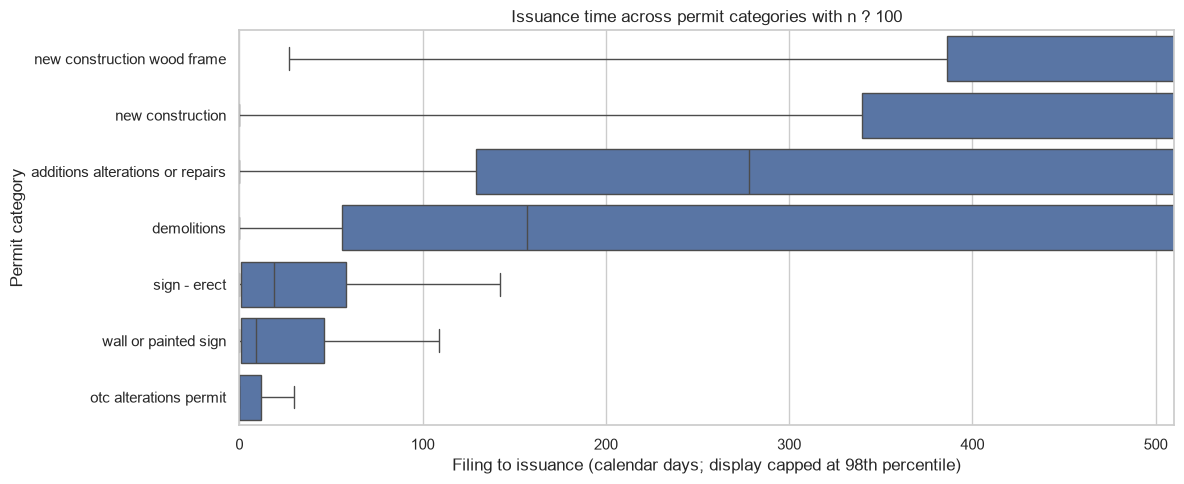

In [6]:
# Plot categories with at least this many valid durations; state/report threshold with results.
MIN_GROUP_N = 100
counts = valid["work_category"].value_counts()
common_categories = counts[counts >= MIN_GROUP_N].index
plot_data = valid.loc[valid["work_category"].isin(common_categories)]
order = (plot_data.groupby("work_category", observed=True)["issuance_days"]
         .median().sort_values(ascending=False).index)
plt.figure(figsize=(12, max(5, .35 * len(order))))
sns.boxplot(data=plot_data, y="work_category", x="issuance_days", order=order, showfliers=False)
plt.xlim(left=0, right=plot_data["issuance_days"].quantile(.98))
plt.xlabel("Filing to issuance (calendar days; display capped at 98th percentile)")
plt.ylabel("Permit category")
plt.title("Issuance time across permit categories with n ? 100")
plt.tight_layout()
plt.show()


### What this shows

The boxplot makes the difference in typical durations and spread visible for categories with at least 100 usable records. The horizontal axis is capped at the 98th percentile **for display only**, so the longest valid durations are not deleted from the analysis. The wide boxes and tails for construction and additions categories show substantial variation even within a category.


## 5. Hypotheses and test plan

**Question:** Do filing-to-issuance times differ across permit categories?

- **H?:** Filing-to-issuance duration distributions are the same across categories.
- **H?:** At least one category has a different duration distribution.
- **Outcome:** `filing_to_issuance_days`, calendar days, valid recorded intervals.
- **Groups:** `permit_type_definition` (or permit code fallback).
- **Primary test:** Kruskal?Wallis rank test across categories with at least 100 valid observations. The threshold is a practical stability rule and should be reported.

This test compares distributions; it is not strictly a test of medians. Permits may be clustered by parcel and filing time, so the independence assumption is imperfect. The p-value does not measure the size or practical importance of a difference.


In [7]:
MIN_GROUP_N = 100
counts = valid["work_category"].value_counts()
included_categories = counts[counts >= MIN_GROUP_N].index
groups = [valid.loc[valid["work_category"].eq(cat), "issuance_days"].astype(float).to_numpy()
          for cat in included_categories]
print(f"Categories included: {len(groups)}; permits tested: {sum(map(len, groups)):,}")
print(f"Categories omitted for n < {MIN_GROUP_N}: {(counts < MIN_GROUP_N).sum()}")
if len(groups) >= 2:
    kw = stats.kruskal(*groups)
    k, n = len(groups), sum(map(len, groups))
    epsilon_sq = max(0, (kw.statistic - k + 1) / (n - k))
    p_display = "<1e-300 (below floating-point precision)" if kw.pvalue == 0 else f"{kw.pvalue:.3g}"
    print(f"Kruskal-Wallis H={kw.statistic:.3f}, df={k-1}, p={p_display}")
    print(f"Approximate epsilon-squared effect size={epsilon_sq:.4f}")
    print("At alpha=.05:", "evidence of a difference among at least two distributions" if kw.pvalue < .05
          else "insufficient evidence of a difference among category distributions")
else:
    print("Fewer than two categories meet the minimum sample threshold.")


Categories included: 7; permits tested: 143,166
Categories omitted for n < 100: 1
Kruskal-Wallis H=23257.652, df=6, p=<1e-300 (below floating-point precision)
Approximate epsilon-squared effect size=0.1624
At alpha=.05: evidence of a difference among at least two distributions


### What this shows

The Kruskal?Wallis test compares **7 categories** with **143,166 permits** (the small ?grade or quarry or fill or excavate? group, n=34, is excluded under the stated n?100 rule). The statistic is **H=23,257.652**, with 6 degrees of freedom. The computed p-value is below floating-point display precision; it is not literally zero. The approximate epsilon-squared is **0.1624**, indicating that the category differences are not just detectable because the dataset is large, though this is still an observational, unadjusted group comparison.

At the 0.05 level, reject H?: there is strong evidence that at least one category?s issuance-time distribution differs. This overall test does not tell us which pairs differ; that is the purpose of the adjusted follow-up below.


### Pairwise follow-up

Run pairwise Mann?Whitney tests only if the overall test is significant. Holm adjustment accounts for the multiple pairwise comparisons. Interpret these with sample sizes and median differences; adjusted significance alone is not enough.


In [8]:
from itertools import combinations
if len(groups) >= 2 and kw.pvalue < 0.05:
    rows = []
    for a, b in combinations(included_categories, 2):
        x = valid.loc[valid["work_category"].eq(a), "issuance_days"].astype(float)
        y = valid.loc[valid["work_category"].eq(b), "issuance_days"].astype(float)
        p = stats.mannwhitneyu(x, y, alternative="two-sided").pvalue
        rows.append((str(a), str(b), len(x), len(y), x.median(), y.median(), p))
    pairwise = pd.DataFrame(rows, columns=["category_a", "category_b", "n_a", "n_b",
        "median_a", "median_b", "p_raw"])
    # Holm step-down adjustment, restored to original row order.
    order_idx = np.argsort(pairwise["p_raw"].to_numpy())
    p_sorted = pairwise.loc[order_idx, "p_raw"].to_numpy()
    adjusted = np.minimum(1, np.maximum.accumulate([(len(p_sorted)-i)*p for i, p in enumerate(p_sorted)]))
    pairwise["p_holm"] = np.nan
    pairwise.loc[order_idx, "p_holm"] = adjusted
    pairwise["median_difference_a_minus_b"] = pairwise["median_a"] - pairwise["median_b"]
    pairwise["p_raw_display"] = pairwise["p_raw"].map(lambda p: "<1e-300" if p == 0 else f"{p:.3g}")
    pairwise["p_holm_display"] = pairwise["p_holm"].map(lambda p: "<1e-300" if p == 0 else f"{p:.3g}")
    shown = pairwise[["category_a", "category_b", "n_a", "n_b", "median_a", "median_b",
                      "median_difference_a_minus_b", "p_raw_display", "p_holm_display"]]
    display(shown.loc[pairwise.sort_values("p_holm").index].round({"median_a": 1, "median_b": 1, "median_difference_a_minus_b": 1}))
else:
    print("No pairwise tests run: first require a significant overall test.")


,category_a,category_b,n_a,n_b,median_a,median_b,median_difference_a_minus_b,p_raw_display,p_holm_display
0,otc alterations permit,additions alterations or repairs,133108,6832,0.0,278.0,-278.0,<1e-300,<1e-300
1,otc alterations permit,sign - erect,133108,2261,0.0,19.0,-19.0,<1e-300,<1e-300
6,additions alterations or repairs,sign - erect,6832,2261,278.0,19.0,259.0,<1e-300,<1e-300
3,otc alterations permit,demolitions,133108,316,0.0,157.0,-157.0,1.53e-192,2.76e-191
4,otc alterations permit,new construction wood frame,133108,221,0.0,620.0,-620.0,2.52e-177,4.28e-176
7,additions alterations or repairs,wall or painted sign,6832,320,278.0,9.0,269.0,1.39e-139,2.23e-138
13,sign - erect,new construction wood frame,2261,221,19.0,620.0,-601.0,2.9e-121,4.35e-120
12,sign - erect,demolitions,2261,316,19.0,157.0,-138.0,1.58e-87,2.21e-86
5,otc alterations permit,new construction,133108,108,0.0,528.5,-528.5,1.23e-85,1.6e-84
16,wall or painted sign,new construction wood frame,320,221,9.0,620.0,-611.0,2.25e-79,2.7e-78


### What this shows

The adjusted pairwise comparisons show that **20 of the 21 category pairs** differ after Holm correction. The one pair without a statistically significant difference is **new construction wood frame vs. new construction**: medians are 620 vs. 528.5 days, but the adjusted p-value is about **0.159**. That is not proof the categories are equivalent; their sample sizes are only 221 and 108 valid durations.

The other large contrasts include OTC alterations (0-day median) versus additions (278 days), demolitions (157 days), and new construction (about 529?620 days). P-values shown as `<1e-300` have underflowed in ordinary floating-point arithmetic and should be read as extremely small, never as exactly zero.


## 6. Sensitivity checks and dimensionality reduction

1. Repeat descriptive summaries within filing year or compare year-stratified patterns; the overall difference may reflect changing permit mix over time.
2. Compare each category's share of valid issuance durations. Non-issued permits are not included in the duration test.
3. Consider a separate binary outcome using `issued_within_365_days` among records with at least 365 days of follow-up and valid chronology. This asks a different question and should be labeled separately.
4. Do not automatically remove extreme but valid durations. If you show capped plots, state that the cap is visual only.

**PCA is not recommended for this hypothesis.** The category itself is the explanatory grouping; reducing category indicators to principal components obscures the group interpretation. If you later build an exploratory model with many numeric predictors, standardize those predictors and exclude identifiers, outcomes, post-filing lifecycle fields, and leakage variables before PCA. Keep PCA separate from this hypothesis test.


In [9]:
# Optional descriptive check: median duration by filing year, for the most common categories.
if len(common_categories):
    year_summary = (valid.loc[valid["work_category"].isin(common_categories)]
        .groupby(["filing_year", "work_category"], observed=True)["issuance_days"]
        .median().unstack("work_category"))
    display(year_summary.round(1))


work_category,additions alterations or repairs,demolitions,new construction,new construction wood frame,otc alterations permit,sign - erect,wall or painted sign
filing_year,,,,,,,
2019,322.0,56.0,617.0,827.0,0.0,14.5,6.5
2020,304.0,154.0,409.0,761.5,1.0,72.0,12.0
2021,351.0,175.0,539.0,567.0,0.0,37.5,63.0
2022,308.0,190.0,452.0,636.0,0.0,10.0,6.0
2023,235.0,298.0,332.0,496.5,0.0,9.0,5.0
2024,130.0,183.5,126.0,294.0,0.0,7.0,5.0


### What this shows

The year-by-category medians add useful context: construction and additions categories generally have long issuance intervals, but their medians move across filing years. For example, new construction wood frame declines from **827 days in 2019** to **294 days in 2024**, while OTC alterations stays around 0?1 day. This is descriptive evidence that year/cohort may matter; the table does not adjust for year or test whether the category effect remains after accounting for it. A year-adjusted model or stratified test would be a sensible next robustness check.


## 7. Record your conclusion

- H?/H? and category definition: [fill in]
- Cleaning decisions and duplicate check: [fill in]
- Valid duration sample, excluded rows, and missing-time rates: [fill in]
- Category sizes, medians, and IQRs: [fill in]
- Kruskal?Wallis statistic, degrees of freedom, p-value, and effect size: [fill in]
- Holm adjusted pairwise findings, if applicable: [fill in]
- Year sensitivity, practical meaning, and limitations: [fill in]

Avoid saying permit category causes longer issuance times. These are administrative elapsed times in observational records.


## Conclusion

In this dataset, **recorded filing-to-issuance times differ substantially across permit categories**. The null hypothesis is rejected by the overall Kruskal?Wallis comparison (H=23,257.652, df=6, p<1e-300 at floating-point precision; approximate epsilon-squared=0.1624). The largest common categories show a meaningful pattern: over-the-counter alterations are typically issued same day, while additions, demolitions, and new construction have much longer median times. Most category pairs differ after Holm adjustment; the two new-construction categories are the exception in this sample.

Read this conclusion as a comparison among records with valid issuance intervals. Valid-duration coverage varies by category, and differences across filing years are visible. The data cannot tell us that the category itself causes longer waits, nor separate agency processing time from applicant response and payment time. A final report should state the category threshold and exclusions and treat year, parcel clustering, and missing issuance times as limitations.
